# Accident Severity Prediction Using Machine Learning

## Objective
The objective of this project is to predict the severity of road accidents using historical accident data. The model will classify accidents into different severity levels and provide insights that can help improve road safety and decision-making.

# Import Required Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries Imported Successfully")

Libraries Imported Successfully


# Load Dataset

In [3]:
df = pd.read_csv("Vehicle_Collision.csv")

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


# First 5 Records

In [4]:
df.head()

,UNIQUE_ID,COLLISION_ID,CRASH_DATE,CRASH_TIME,PERSON_ID,PERSON_TYPE,PERSON_INJURY,VEHICLE_ID,PERSON_AGE,EJECTION,EMOTIONAL_STATUS,BODILY_INJURY,POSITION_IN_VEHICLE,SAFETY_EQUIPMENT,PED_LOCATION,PED_ACTION,COMPLAINT,PED_ROLE,CONTRIBUTING_FACTOR_1,CONTRIBUTING_FACTOR_2,PERSON_SEX
0,10253606,4230743.0,10/24/2019,19:15,84bcb3a7-d201-4c61-9e30-fe29268c1074,Occupant,Injured,19143343.0,27.0,Not Ejected,Conscious,Back,Driver,Lap Belt & Harness,NaN,NaN,Complaint of Pain or Nausea,Driver,NaN,NaN,M
1,10248708,4229547.0,10/26/2019,1:15,a8904763-2870-42f3-865c-b53d8e5156e2,Pedestrian,Injured,NaN,24.0,NaN,Conscious,Shoulder - Upper Arm,NaN,NaN,Pedestrian/Bicyclist/Other Pedestrian at Inter...,Crossing With Signal,None Visible,Pedestrian,Unspecified,Unspecified,F
2,10254556,4230715.0,10/26/2019,8:50,1a085543-ae9d-4a69-8cd0-fb7b33380a8b,Bicyclist,Injured,19143832.0,42.0,Not Ejected,Unknown,Knee-Lower Leg Foot,Driver,Unknown,NaN,NaN,None Visible,Driver,NaN,NaN,M
3,10250834,4230376.0,10/26/2019,19:40,f58fc41f-497e-4f30-bf49-a9a80adec8b2,Bicyclist,Injured,19141949.0,36.0,Not Ejected,Conscious,Back,Driver,NaN,NaN,NaN,Internal,Driver,NaN,NaN,M
4,10252474,4229773.0,10/26/2019,16:50,4bf13d12-8d7a-4cb0-997f-dd6a8b1adca6,Occupant,Injured,19142773.0,50.0,Not Ejected,Conscious,Head,"Front passenger, if two or more persons, inclu...",Lap Belt & Harness,NaN,NaN,Complaint of Pain or Nausea,Passenger,NaN,NaN,F


# Number of Rows and Columns

In [5]:
print("Dataset Shape :", df.shape)

print("Number of Rows :", df.shape[0])

print("Number of Columns :", df.shape[1])

Dataset Shape : (230660, 21)
Number of Rows : 230660
Number of Columns : 21


# Dataset Information

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 230660 entries, 0 to 230659
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   UNIQUE_ID              230660 non-null  object 
 1   COLLISION_ID           230656 non-null  float64
 2   CRASH_DATE             230656 non-null  object 
 3   CRASH_TIME             230656 non-null  object 
 4   PERSON_ID              230653 non-null  object 
 5   PERSON_TYPE            230656 non-null  object 
 6   PERSON_INJURY          230656 non-null  object 
 7   VEHICLE_ID             181937 non-null  float64
 8   PERSON_AGE             229663 non-null  float64
 9   EJECTION               102787 non-null  object 
 10  EMOTIONAL_STATUS       126918 non-null  object 
 11  BODILY_INJURY          126959 non-null  object 
 12  POSITION_IN_VEHICLE    102906 non-null  object 
 13  SAFETY_EQUIPMENT       90120 non-null   object 
 14  PED_LOCATION           26292 non-nul

# Numerical Summary

In [7]:
df.describe()


,COLLISION_ID,VEHICLE_ID,PERSON_AGE
count,2.306560e+05,1.819370e+05,229663.000000
mean,2.824113e+06,1.567930e+07,36.474029
std,1.497211e+06,3.051295e+06,84.924692
min,3.900000e+01,6.029470e+05,-997.000000
25%,2.812695e+06,1.353522e+07,23.000000
50%,3.474966e+06,1.714574e+07,33.000000
75%,3.873819e+06,1.795996e+07,49.000000
max,4.695378e+06,2.058575e+07,9999.000000


# Data Types of Columns


In [8]:
df.dtypes

UNIQUE_ID                 object
COLLISION_ID             float64
CRASH_DATE                object
CRASH_TIME                object
PERSON_ID                 object
PERSON_TYPE               object
PERSON_INJURY             object
VEHICLE_ID               float64
PERSON_AGE               float64
EJECTION                  object
EMOTIONAL_STATUS          object
BODILY_INJURY             object
POSITION_IN_VEHICLE       object
SAFETY_EQUIPMENT          object
PED_LOCATION              object
PED_ACTION                object
COMPLAINT                 object
PED_ROLE                  object
CONTRIBUTING_FACTOR_1     object
CONTRIBUTING_FACTOR_2     object
PERSON_SEX                object
dtype: object

# Missing Values Count

In [12]:
missing_values = df.isnull().sum()

In [13]:
missing_values[missing_values > 0].sort_values(ascending=False)

CONTRIBUTING_FACTOR_2    205477
CONTRIBUTING_FACTOR_1    205452
PED_ACTION               204430
PED_LOCATION             204368
SAFETY_EQUIPMENT         140540
EJECTION                 127873
POSITION_IN_VEHICLE      127754
PERSON_SEX               103768
EMOTIONAL_STATUS         103742
BODILY_INJURY            103701
COMPLAINT                103687
PED_ROLE                 103687
VEHICLE_ID                48723
PERSON_AGE                  997
PERSON_ID                     7
CRASH_DATE                    4
PERSON_INJURY                 4
PERSON_TYPE                   4
CRASH_TIME                    4
COLLISION_ID                  4
dtype: int64

# Missing Value Percentage

In [14]:
missing_percentage = (df.isnull().sum()/len(df))*100


In [15]:
missing_percentage[missing_percentage > 0].sort_values(ascending=False)


CONTRIBUTING_FACTOR_2    89.082199
CONTRIBUTING_FACTOR_1    89.071360
PED_ACTION               88.628284
PED_LOCATION             88.601405
SAFETY_EQUIPMENT         60.929507
EJECTION                 55.437874
POSITION_IN_VEHICLE      55.386283
PERSON_SEX               44.987427
EMOTIONAL_STATUS         44.976155
BODILY_INJURY            44.958380
COMPLAINT                44.952311
PED_ROLE                 44.952311
VEHICLE_ID               21.123298
PERSON_AGE                0.432238
PERSON_ID                 0.003035
CRASH_DATE                0.001734
PERSON_INJURY             0.001734
PERSON_TYPE               0.001734
CRASH_TIME                0.001734
COLLISION_ID              0.001734
dtype: float64

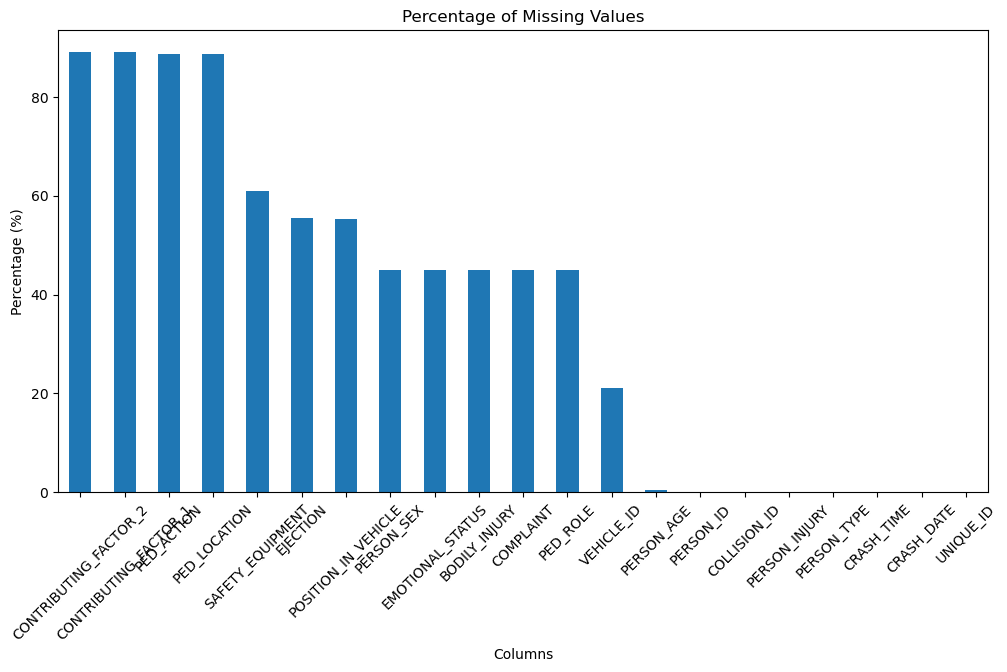

In [17]:
missing_percent = (df.isnull().sum() / len(df)) * 100

plt.figure(figsize=(12,6))
missing_percent.sort_values(ascending=False).plot(kind='bar')

plt.title("Percentage of Missing Values")
plt.ylabel("Percentage (%)")
plt.xlabel("Columns")
plt.xticks(rotation=45)
plt.show()

In [ ]:
duplicates = df.duplicated().sum()
print("Duplicate Records :", duplicates)

Duplicate Records : 0


In [ ]:
df = df.drop_duplicates()
print("New Shape :", df.shape)

New Shape : (230660, 21)


### Observation

- The dataset contains 0 duplicate records.
- Therefore, no duplicate removal was required.
- Data quality is good with respect to duplicate entries.

In [21]:
df.columns

Index(['UNIQUE_ID', 'COLLISION_ID', 'CRASH_DATE', 'CRASH_TIME', 'PERSON_ID',
       'PERSON_TYPE', 'PERSON_INJURY', 'VEHICLE_ID', 'PERSON_AGE', 'EJECTION',
       'EMOTIONAL_STATUS', 'BODILY_INJURY', 'POSITION_IN_VEHICLE',
       'SAFETY_EQUIPMENT', 'PED_LOCATION', 'PED_ACTION', 'COMPLAINT',
       'PED_ROLE', 'CONTRIBUTING_FACTOR_1', 'CONTRIBUTING_FACTOR_2',
       'PERSON_SEX'],
      dtype='object')

In [22]:
df['PERSON_INJURY'].value_counts()

PERSON_INJURY
Injured    229633
Killed       1023
Name: count, dtype: int64

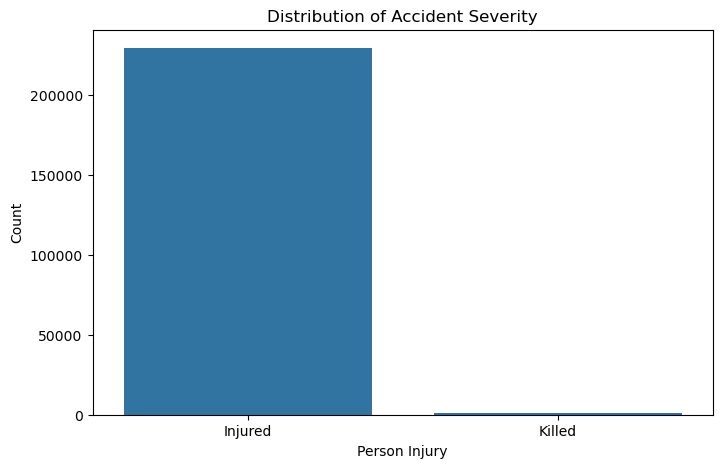

In [23]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='PERSON_INJURY',
    data=df
)

plt.title('Distribution of Accident Severity')
plt.xlabel('Person Injury')
plt.ylabel('Count')

plt.show()

In [24]:
injury_percent = round(
    df['PERSON_INJURY'].value_counts(normalize=True)*100,
    2
)

print(injury_percent)

PERSON_INJURY
Injured    99.56
Killed      0.44
Name: proportion, dtype: float64


### Observation

- The target variable is highly imbalanced.
- Approximately 99.56% of records belong to the "Injured" category.
- Only 0.44% of records belong to the "Killed" category.
- This imbalance can bias machine learning models toward predicting the majority class.
- Class balancing techniques such as class weights, oversampling, or SMOTE should be considered during model training.

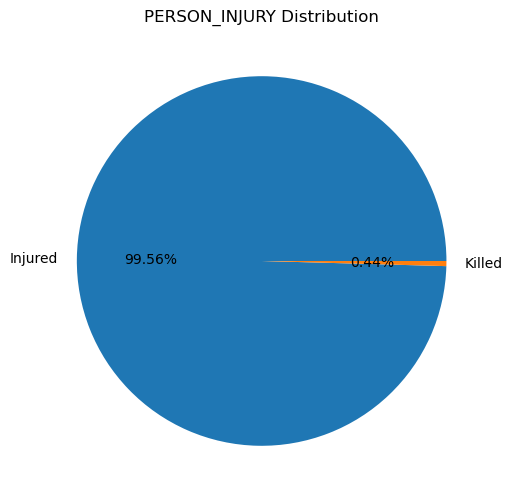

In [26]:
plt.figure(figsize=(6,6))

df['PERSON_INJURY'].value_counts().plot(
    kind='pie',
    autopct='%1.2f%%'
)

plt.title('PERSON_INJURY Distribution')
plt.ylabel('')

plt.show()

Data Cleaning & Preprocessing

In [44]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

In [45]:
df = pd.read_csv("Vehicle_Collision.csv")
df.head()

,UNIQUE_ID,COLLISION_ID,CRASH_DATE,CRASH_TIME,PERSON_ID,PERSON_TYPE,PERSON_INJURY,VEHICLE_ID,PERSON_AGE,EJECTION,...,BODILY_INJURY,POSITION_IN_VEHICLE,SAFETY_EQUIPMENT,PED_LOCATION,PED_ACTION,COMPLAINT,PED_ROLE,CONTRIBUTING_FACTOR_1,CONTRIBUTING_FACTOR_2,PERSON_SEX
0,10253606,4230743.0,10/24/2019,19:15,84bcb3a7-d201-4c61-9e30-fe29268c1074,Occupant,Injured,19143343.0,27.0,Not Ejected,...,Back,Driver,Lap Belt & Harness,NaN,NaN,Complaint of Pain or Nausea,Driver,NaN,NaN,M
1,10248708,4229547.0,10/26/2019,1:15,a8904763-2870-42f3-865c-b53d8e5156e2,Pedestrian,Injured,NaN,24.0,NaN,...,Shoulder - Upper Arm,NaN,NaN,Pedestrian/Bicyclist/Other Pedestrian at Inter...,Crossing With Signal,None Visible,Pedestrian,Unspecified,Unspecified,F
2,10254556,4230715.0,10/26/2019,8:50,1a085543-ae9d-4a69-8cd0-fb7b33380a8b,Bicyclist,Injured,19143832.0,42.0,Not Ejected,...,Knee-Lower Leg Foot,Driver,Unknown,NaN,NaN,None Visible,Driver,NaN,NaN,M
3,10250834,4230376.0,10/26/2019,19:40,f58fc41f-497e-4f30-bf49-a9a80adec8b2,Bicyclist,Injured,19141949.0,36.0,Not Ejected,...,Back,Driver,NaN,NaN,NaN,Internal,Driver,NaN,NaN,M
4,10252474,4229773.0,10/26/2019,16:50,4bf13d12-8d7a-4cb0-997f-dd6a8b1adca6,Occupant,Injured,19142773.0,50.0,Not Ejected,...,Head,"Front passenger, if two or more persons, inclu...",Lap Belt & Harness,NaN,NaN,Complaint of Pain or Nausea,Passenger,NaN,NaN,F


In [46]:
df_clean = df.copy()

In [47]:
df_clean = df_clean.dropna(subset=['PERSON_INJURY'])

print(df_clean.shape)

(230656, 21)


In [48]:
drop_cols = [
    'UNIQUE_ID',
    'COLLISION_ID',
    'PERSON_ID',
    'VEHICLE_ID'
]

df_clean = df_clean.drop(columns=drop_cols)

print(df_clean.columns.tolist())

['CRASH_DATE', 'CRASH_TIME', 'PERSON_TYPE', 'PERSON_INJURY', 'PERSON_AGE', 'EJECTION', 'EMOTIONAL_STATUS', 'BODILY_INJURY', 'POSITION_IN_VEHICLE', 'SAFETY_EQUIPMENT', 'PED_LOCATION', 'PED_ACTION', 'COMPLAINT', 'PED_ROLE', 'CONTRIBUTING_FACTOR_1', 'CONTRIBUTING_FACTOR_2', 'PERSON_SEX']


In [49]:
X = df_clean.drop('PERSON_INJURY', axis=1)

y = df_clean['PERSON_INJURY'].map({
    'Injured': 0,
    'Killed': 1
})

In [50]:
print(y.isnull().sum())

print(y.value_counts())

0
PERSON_INJURY
0    229633
1      1023
Name: count, dtype: int64


In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [52]:
num_cols = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include='object'
).columns.tolist()

print("Numerical Columns")
print(num_cols)

print("\nCategorical Columns")
print(cat_cols)

Numerical Columns
['PERSON_AGE']

Categorical Columns
['CRASH_DATE', 'CRASH_TIME', 'PERSON_TYPE', 'EJECTION', 'EMOTIONAL_STATUS', 'BODILY_INJURY', 'POSITION_IN_VEHICLE', 'SAFETY_EQUIPMENT', 'PED_LOCATION', 'PED_ACTION', 'COMPLAINT', 'PED_ROLE', 'CONTRIBUTING_FACTOR_1', 'CONTRIBUTING_FACTOR_2', 'PERSON_SEX']


In [53]:
for col in cat_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

In [54]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

In [55]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [56]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [57]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [58]:
print("Training Shape:", X_train_processed.shape)

print("Testing Shape:", X_test_processed.shape)

Training Shape: (184524, 4561)
Testing Shape: (46132, 4561)
